## Scaled Dot Product Attention 구현

이 셀은 `ScaledDotProductAttention` 클래스를 정의합니다. 이 클래스는 트랜스포머 아키텍처의 핵심 구성 요소인 어텐션 메커니즘을 구현합니다. 입력으로 Query (Q), Key (K), Value (V)를 받아 어텐션 스코어를 계산하고, 이를 스케일링한 후 소프트맥스 함수를 적용하여 어텐션 가중치를 얻습니다. 최종적으로 어텐션 가중치와 V를 곱하여 컨텍스트 벡터를 생성합니다.

In [3]:
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
import math

class ScaledDotProductAttention(nn.Module):
    def __init__(self, d_head):
        super().__init__()
        self.d_head = d_head

    def forward(self, Q, K, V, attn_mask=None):
        attention_scores = Q @ K.transpose(-2, -1)

        if attn_mask is not None:
            attention_scores = attention_scores.masked_fill(attn_mask == 0, float("-inf"))

        scaled_scores = attention_scores / math.sqrt(self.d_head)
        attention_weights = F.softmax(scaled_scores, dim=-1)
        context_vector = attention_weights @ V
        return context_vector, attention_scores, scaled_scores, attention_weights

## 간단한 트랜스포머 블록 (SimpleTransformer) 구현

이 셀은 `SimpleTransformer` 클래스를 정의합니다. 이 클래스는 멀티헤드 어텐션을 제외한 기본적인 트랜스포머 블록의 구조를 따릅니다.

임베딩을 입력으로 받아 Query, Key, Value를 생성하고, 앞에서 정의한 `ScaledDotProductAttention`을 사용하여 어텐션을 수행합니다.

이후 잔차 연결(Residual Connection)과 레이어 정규화(Layer Normalization), 그리고 피드 포워드 네트워크(Feed-Forward Network)를 적용하여 최종 출력을 생성합니다.

#### **(1) Scaled Dot Product Attention**
어텐션은 다음과 같이 계산됩니다:
$$ \text{Attention}(Q, K, V) = \text{softmax}\left(\frac{QK^T}{\sqrt{d_k}}\right)V $$
여기서 $Q$는 쿼리 행렬, $K$는 키 행렬, $V$는 값 행렬, $d_k$는 키 벡터의 차원입니다.


#### **(2) Feed-Forward Network (FFN)**
피드 포워드 네트워크는 두 개의 선형 변환과 비선형 활성화 함수로 구성됩니다:
$$ \text{FFN}(x) = \max(0, xW_1 + b_1)W_2 + b_2 $$


#### **(3) Add & Layer Normalization (Add & Norm)**
트랜스포머 블록에서는 각 서브레이어(어텐션, FFN)의 출력에 잔차 연결(Residual Connection)을 적용한 후 레이어 정규화(Layer Normalization)를 수행합니다.  
**잔차 연결이 가능하려면 서브레이어의 입력과 출력의 차원이 같아야 합니다.**   
이는 다음 두 단계로 이루어집니다:

1.  **잔차 연결 (Add):** 서브레이어의 입력 $x$와 출력 sublayer(x)를 더합니다. x + sublayer(x)   

2.  **레이어 정규화 (LayerNorm):** 잔차 연결된 결과를 정규화합니다. 레이어 정규화는 각 레이어의 입력을 정규화하여 학습을 안정화합니다:
$$Z = LayerNorm(x+sublayer(x))$$

In [4]:
class SimpleTransformer(nn.Module):
    def __init__(self, d_model):
        super().__init__()
        self.d_model = d_model

        # WQ, WK, WV 학습 파라미터
        self.W_q = nn.Parameter(torch.randn(d_model, d_model))
        self.W_k = nn.Parameter(torch.randn(d_model, d_model))
        self.W_v = nn.Parameter(torch.randn(d_model, d_model))

        # Scaled dot product attention
        self.attention = ScaledDotProductAttention(d_model)

        # FFN
        self.W_ffn1 = nn.Parameter(torch.randn(d_model, d_model * 4))
        self.b_ffn1 = nn.Parameter(torch.randn(d_model * 4))
        self.W_ffn2 = nn.Parameter(torch.randn(d_model * 4, d_model))
        self.b_ffn2 = nn.Parameter(torch.randn(d_model))

        # Add & Norm
        self.norm1 = nn.LayerNorm(d_model)
        self.norm2 = nn.LayerNorm(d_model)

    def forward(self, embeddings):
        Q = embeddings @ self.W_q
        K = embeddings @ self.W_k
        V = embeddings @ self.W_v

        context_vector , attention_scores, scaled_scores, attention_weights = self.attention(Q, K, V)

        # 잔차 연결(Add): 원본 입력(embeddings) + 어텐션 결과(context_vector)
        norm1_out = self.norm1(embeddings + context_vector)

        # FFN 계산
        f_out = F.relu(norm1_out @ self.W_ffn1 + self.b_ffn1) @ self.W_ffn2 + self.b_ffn2

        # 잔차 연결(Add): 첫 번째 결과(norm1_out) + FFN 결과(f_out)
        final_out = self.norm2(norm1_out + f_out)

        return Q, K, V, attention_scores, attention_weights, context_vector, final_out

## (3) 트랜스포머 모델 실행 및 결과 확인

이 셀은 `SimpleTransformer` 모델을 초기화하고, 예시 입력 `X`를 모델에 통과시켜 결과를 확인합니다.   
`d_model`은 모델의 차원수를 정의하고, `X`는 임의의 입력 임베딩을 나타냅니다.  

모델을 실행한 후 Query (Q), Key (K), Value (V), 어텐션 스코어, 어텐션 가중치, 컨텍스트 벡터, 그리고 최종 출력을 출력합니다.

In [5]:
d_model = 4
X = torch.tensor(
    [[0.3, 0.2, 0.8, 0.6], # I
     [0.1, 0.3, 0.7, 0.9], # love
     [0.6, 0.4, 0.5, 0.8], # this
     [0.7, 0.1, 0.4, 0.7]]) # movie

transformer_model = SimpleTransformer(d_model)
Q, K, V, attention_scores, attention_weights, context_vector, final_out = transformer_model(X)

print("Input Embeddings (X):")
print(X)
print("\nQuery (Q):")
print(Q)
print("\nKey (K):")
print(K)
print("\nValue (V):")
print(V)
print("\nAttention Scores:")
print(attention_scores)
print("\nAttention Weights:")
print(attention_weights)
print("\nContext Vector:")
print(context_vector)
print("\nFinal Output (after Transformer Block):")
print(final_out)

Input Embeddings (X):
tensor([[0.3000, 0.2000, 0.8000, 0.6000],
        [0.1000, 0.3000, 0.7000, 0.9000],
        [0.6000, 0.4000, 0.5000, 0.8000],
        [0.7000, 0.1000, 0.4000, 0.7000]])

Query (Q):
tensor([[-0.7248,  1.0322,  1.7138,  0.3154],
        [-0.5863,  1.2106,  2.1429,  0.5864],
        [-0.9902,  0.8503,  2.3756,  0.9300],
        [-1.6158,  0.2854,  1.3337,  0.7330]], grad_fn=<MmBackward0>)

Key (K):
tensor([[ 0.1626, -0.0880, -0.1480, -0.9297],
        [-0.2539, -0.1718,  0.7711, -1.1758],
        [-0.5721, -0.2512,  0.0587, -0.9840],
        [-0.1734, -0.7926, -0.2246, -0.9809]], grad_fn=<MmBackward0>)

Value (V):
tensor([[-0.0156,  1.6481,  1.3808,  0.4698],
        [-0.1866,  1.1407,  2.1197,  0.1172],
        [ 0.3393,  1.6910,  1.3299,  0.5532],
        [ 0.4291,  1.6960,  0.9083,  0.5735]], grad_fn=<MmBackward0>)

Attention Scores:
tensor([[-0.7556,  0.9573, -0.0543, -1.3867],
        [-1.0642,  0.9039, -0.4198, -1.9143],
        [-1.4521,  0.8437, -0.4227, -1.9

### **(4) 결과 시각화**

입력 문장: I love this movie



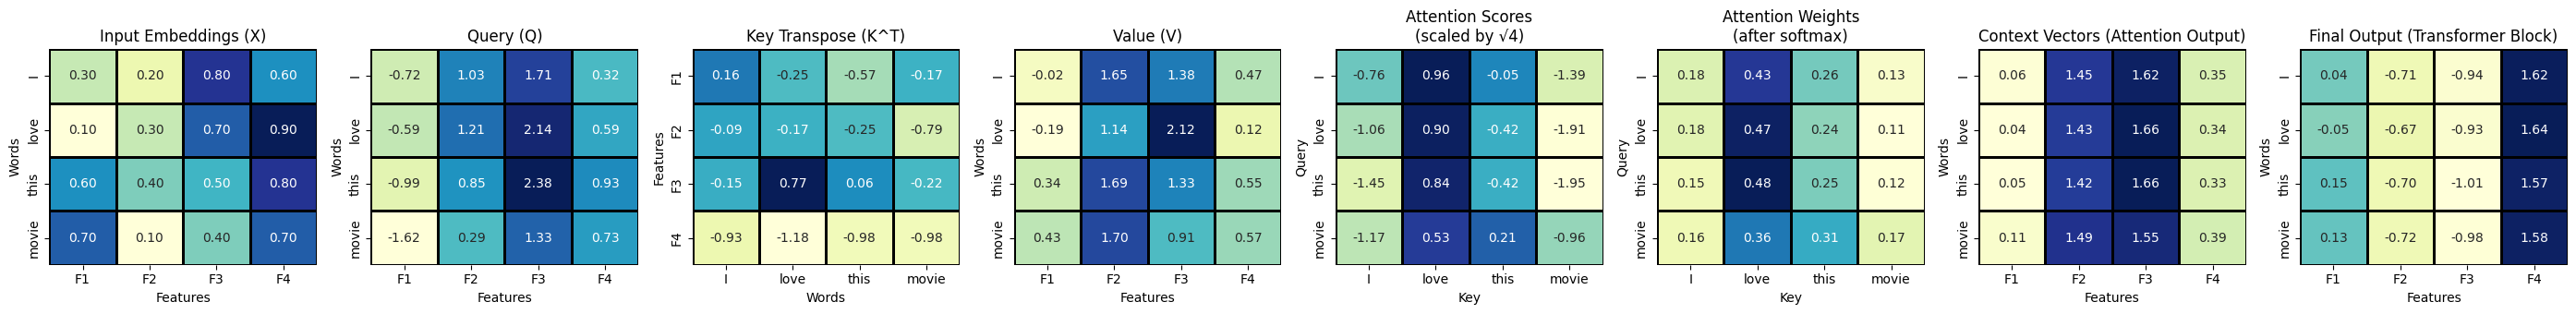


√d_k = √4 = 2.0000
정규화는 attention scores의 크기를 줄여 softmax의 gradient vanishing을 방지합니다.


In [6]:
import torch
import torch.nn.functional as F
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

def plot_attention_process(embeddings, Q_mat, K_mat_T, V_mat, sentence, attention_scores, attention_weights, context_vector_out, final_out):
    """8개의 히트맵을 1x8 서브플롯으로 시각화"""
    fig, axes = plt.subplots(1, 8, figsize=(28, 3.5)) # 서브플롯 개수 6 -> 8으로 증가

    # 공통 설정
    common_params = {'annot': True, 'cbar': False, 'cmap': 'YlGnBu', 'linecolor': 'black','linewidths': 1, 'fmt': '.2f'    }

    # Feature names for x-axis labels
    feature_names = [f'F{i+1}' for i in range(embeddings.shape[1])]
    d_k = embeddings.shape[-1]

    # 1. Input Embeddings (axes[0])
    sns.heatmap(embeddings.detach().numpy(), xticklabels=feature_names,  yticklabels=sentence, ax=axes[0], **common_params)
    axes[0].set_xlabel('Features')
    axes[0].set_ylabel('Words')
    axes[0].set_title('Input Embeddings (X)')

    # 2. Query (Q) (axes[1])
    sns.heatmap(Q_mat.detach().numpy(), xticklabels=feature_names, yticklabels=sentence, ax=axes[1], **common_params)
    axes[1].set_xlabel('Features')
    axes[1].set_ylabel('Words')
    axes[1].set_title('Query (Q)')

    # 3. Key Transpose (K^T) (axes[2])
    sns.heatmap(K_mat_T.detach().numpy(), xticklabels=sentence, yticklabels=feature_names, ax=axes[2], **common_params)
    axes[2].set_xlabel('Words')
    axes[2].set_ylabel('Features')
    axes[2].set_title('Key Transpose (K^T)')

    # 4. Value (V) (axes[3])
    sns.heatmap(V_mat.detach().numpy(), xticklabels=feature_names, yticklabels=sentence, ax=axes[3], **common_params)
    axes[3].set_xlabel('Features')
    axes[3].set_ylabel('Words')
    axes[3].set_title('Value (V)')

    # 5. Attention Scores (axes[4])
    sns.heatmap(attention_scores.detach().numpy(), xticklabels=sentence, yticklabels=sentence, ax=axes[4], **common_params)
    axes[4].set_xlabel('Key')
    axes[4].set_ylabel('Query')
    axes[4].set_title(f'Attention Scores\n(scaled by √{d_k})')

    # 6. Attention Weights (axes[5])
    sns.heatmap(attention_weights.detach().numpy(), xticklabels=sentence, yticklabels=sentence, ax=axes[5], **common_params)
    axes[5].set_xlabel('Key')
    axes[5].set_ylabel('Query')
    axes[5].set_title('Attention Weights\n(after softmax)')

    # 7. Context Vectors (Attention Output) (axes[6])
    sns.heatmap(context_vector_out.detach().numpy(), xticklabels=feature_names, yticklabels=sentence, ax=axes[6], **common_params)
    axes[6].set_xlabel('Features')
    axes[6].set_ylabel('Words')
    axes[6].set_title('Context Vectors (Attention Output)')

    # 8. Output (Final Transformer Block Output) (axes[7])
    sns.heatmap(final_out.detach().numpy(), xticklabels=feature_names, yticklabels=sentence, ax=axes[7], **common_params)
    axes[7].set_xlabel('Features')
    axes[7].set_ylabel('Words')
    axes[7].set_title('Final Output (Transformer Block)')

    plt.tight_layout()
    plt.show()

# 실행
sentence = ["I", "love", "this", "movie"]
print(f"입력 문장: {' '.join(sentence)}\n")

# 시각화 함수 호출 수정: K.transpose(-2, -1) 추가
plot_attention_process(X, Q, K.transpose(-2, -1), V, sentence, attention_scores, attention_weights, context_vector, final_out)

# d_k 정규화의 효과 확인
print(f"\n√d_k = √{X.shape[-1]} = {np.sqrt(X.shape[-1]):.4f}")
print("정규화는 attention scores의 크기를 줄여 softmax의 gradient vanishing을 방지합니다.")

### (5) 3차원 입력으로 트랜스포머 모델 실행 및 결과 확인

이전 예시와 동일하게 `SimpleTransformer` 모델을 초기화하고, `d_model`을 3으로 설정하여 3차원 입력 `X`를 모델에 통과시켜 결과를 확인합니다. 이를 통해 차원의 변화에 따른 각 값들의 변화를 더 명확하게 볼 수 있습니다.

In [7]:
d_model_3d = 3
X_3d = torch.tensor(
    [[0.3, 0.2, 0.8], # I
     [0.1, 0.3, 0.7], # love
     [0.6, 0.4, 0.5], # this
     [0.7, 0.1, 0.4]]) # movie

transformer_model_3d = SimpleTransformer(d_model_3d)
Q_3d, K_3d, V_3d, attention_scores_3d, attention_weights_3d, context_vector_3d, final_out_3d = transformer_model_3d(X_3d)

print("Input Embeddings (X) [3D]:")
print(X_3d)
print("\nQuery (Q) [3D]:")
print(Q_3d)
print("\nKey (K) [3D]:")
print(K_3d)
print("\nValue (V) [3D]:")
print(V_3d)
print("\nAttention Scores [3D]:")
print(attention_scores_3d)
print("\nAttention Weights [3D]:")
print(attention_weights_3d)
print("\nContext Vector [3D]:")
print(context_vector_3d)
print("\nFinal Output (after Transformer Block) [3D]:")
print(final_out_3d)

Input Embeddings (X) [3D]:
tensor([[0.3000, 0.2000, 0.8000],
        [0.1000, 0.3000, 0.7000],
        [0.6000, 0.4000, 0.5000],
        [0.7000, 0.1000, 0.4000]])

Query (Q) [3D]:
tensor([[ 0.1515,  1.1600, -1.3244],
        [ 0.0416,  1.0290, -0.9773],
        [ 0.2713,  0.7590, -1.3352],
        [ 0.3449,  0.5823, -1.3100]], grad_fn=<MmBackward0>)

Key (K) [3D]:
tensor([[ 1.0398e+00,  1.5805e+00, -7.2566e-04],
        [ 4.9317e-01,  1.4460e+00,  8.4897e-02],
        [ 8.6595e-01,  1.2827e+00,  1.0532e+00],
        [ 1.3290e+00,  9.0169e-01,  6.1785e-01]], grad_fn=<MmBackward0>)

Value (V) [3D]:
tensor([[ 1.3055, -0.2930, -1.2021],
        [ 1.4467, -0.5039, -1.3425],
        [ 0.8925,  0.5191, -0.8691],
        [ 0.2290,  0.7440, -0.2284]], grad_fn=<MmBackward0>)

Attention Scores [3D]:
tensor([[ 1.9919,  1.6397,  0.2243,  0.4291],
        [ 1.6703,  1.4255,  0.3267,  0.3793],
        [ 1.4827,  1.1180, -0.1977,  0.2201],
        [ 1.2799,  0.9009, -0.3340,  0.1741]], grad_fn=<MmBac

### (6) 3차원 입력 결과 시각화

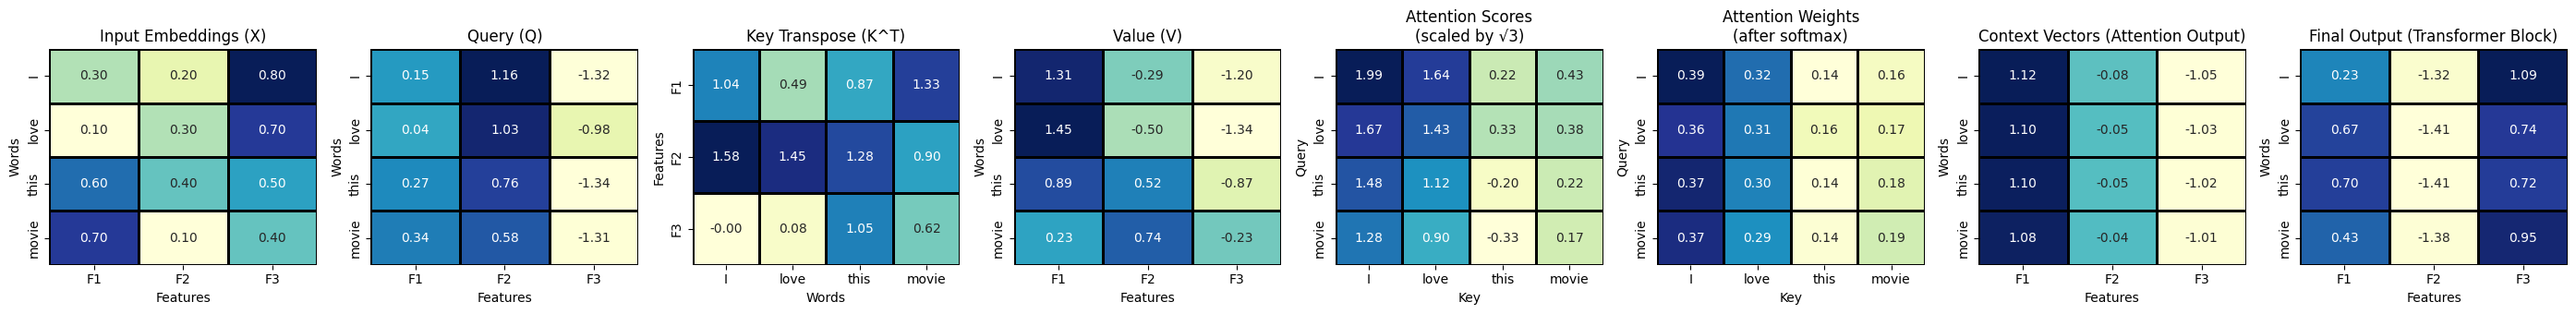


√d_k = √3 = 1.7321
정규화는 attention scores의 크기를 줄여 softmax의 gradient vanishing을 방지합니다.


In [8]:
# 시각화 함수 호출: K.transpose(-2, -1) 추가 (3D 데이터)
plot_attention_process(X_3d, Q_3d, K_3d.transpose(-2, -1), V_3d, sentence, attention_scores_3d, attention_weights_3d, context_vector_3d, final_out_3d)

# d_k 정규화의 효과 확인 (3D 데이터)
print(f"\n√d_k = √{X_3d.shape[-1]} = {np.sqrt(X_3d.shape[-1]):.4f}")
print("정규화는 attention scores의 크기를 줄여 softmax의 gradient vanishing을 방지합니다.")